## Core Architecture of a PINN



Standard neural networks minimize a loss based purely on data ($Loss_{data}$). A PINN minimizes a combined loss function:$$Loss_{total} = Loss_{data} + Loss_{physics}$$

$$\frac{du}{dt} = -k u(t)$$

In [1]:
import torch
import torch.nn as nn
import numpy as np

# Define a simple multi-layer perceptron
class PINN(nn.Module):
    def __init__(self):
        super(PINN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 20),
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 1)
        )
        
    def forward(self, t):
        return self.net(t)

# Initialize model and optimizer
model = PINN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Hyperparameters
k = 2.0

In [2]:
def physics_loss(model, t_collocation):
    t_collocation.requires_grad_(True)
    u = model(t_collocation)
    
    # Compute the time derivative du/dt
    du_dt = torch.autograd.grad(
        u, t_collocation, 
        grad_outputs=torch.ones_like(u), 
        create_graph=True
    )[0]
    
    # ODE residual: du/dt + k * u = 0
    residual = du_dt + k * u
    return torch.mean(residual**2)

In [3]:
# Initial condition data point: t = 0, u = 1
t_ic = torch.tensor([[0.0]], dtype=torch.float32)
u_ic = torch.tensor([[1.0]], dtype=torch.float32)

# Collocation points for enforcing physics across the domain
t_collocation = torch.linspace(0, 1, 100, dtype=torch.float32).view(-1, 1)

epochs = 1000
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # 1. Initial condition loss
    pred_ic = model(t_ic)
    loss_data = torch.mean((pred_ic - u_ic)**2)
    
    # 2. Physics residual loss
    loss_pde = physics_loss(model, t_collocation)
    
    # Total loss
    loss = loss_data + loss_pde
    
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 200 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Total Loss: {loss.item():.6f} | Data Loss: {loss_data.item():.6f} | PDE Loss: {loss_pde.item():.6f}")

Epoch 200/1000 | Total Loss: 0.000102 | Data Loss: 0.000000 | PDE Loss: 0.000101
Epoch 400/1000 | Total Loss: 0.000010 | Data Loss: 0.000000 | PDE Loss: 0.000010
Epoch 600/1000 | Total Loss: 0.000003 | Data Loss: 0.000000 | PDE Loss: 0.000003
Epoch 800/1000 | Total Loss: 0.000002 | Data Loss: 0.000000 | PDE Loss: 0.000002
Epoch 1000/1000 | Total Loss: 0.000003 | Data Loss: 0.000000 | PDE Loss: 0.000003


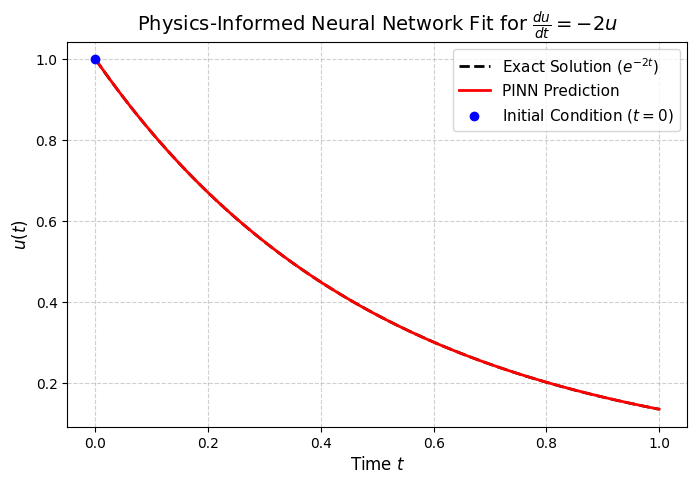

In [4]:
import matplotlib.pyplot as plt

# Generate high-resolution test points across the domain [0, 1]
t_test = torch.linspace(0, 1, 100, dtype=torch.float32).view(-1, 1)

# Get predictions from the trained PINN model
model.eval()
with torch.no_grad():
    u_pred = model(t_test)

# Compute the exact analytical solution: u(t) = e^(-2t)
u_exact = torch.exp(-2.0 * t_test)

# Plotting the comparison
plt.figure(figsize=(8, 5))
plt.plot(t_test.numpy(), u_exact.numpy(), 'k--', label='Exact Solution ($e^{-2t}$)', linewidth=2)
plt.plot(t_test.numpy(), u_pred.numpy(), 'r-', label='PINN Prediction', linewidth=2)
plt.scatter(t_ic.numpy(), u_ic.numpy(), color='blue', label='Initial Condition ($t=0$)', zorder=5)

plt.xlabel('Time $t$', fontsize=12)
plt.ylabel('$u(t)$', fontsize=12)
plt.title('Physics-Informed Neural Network Fit for $\\frac{du}{dt} = -2u$', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Moving from an Ordinary Differential Equation (ODE) to a Partial Differential Equation (PDE) is the natural next step. Let's model the 1D Heat Equation, which describes how heat (or temperature) diffuses through a medium over space and time:$$\frac{\partial u}{\partial t} = \nu \frac{\partial^2 u}{\partial x^2}$$Where $u(x,t)$ is the temperature, $x$ is position, $t$ is time, and $\nu$ is the thermal diffusivity constant. Unlike our previous ODE model which took only time $t$, this neural network takes two inputs ($x$ and $t$) and computes higher-order derivatives with respect to both space and time.

In [5]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Define PINN for 2 inputs (x, t) -> 1 output (u)
class HeatPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        
    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        return self.net(inputs)

model = HeatPINN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
nu = 0.05  # Thermal diffusivity

In [6]:
def physics_loss(model, x, t, nu):
    x.requires_grad_(True)
    t.requires_grad_(True)
    
    u = model(x, t)
    
    # First derivatives
    u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    
    # Second spatial derivative (u_xx)
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    
    # PDE Residual: u_t - nu * u_xx = 0
    residual = u_t - nu * u_xx
    return torch.mean(residual**2)

In [7]:
# Generate training collocation points across space-time domain
epochs = 2000
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # 1. Collocation points for PDE interior
    x_col = torch.rand(500, 1) * 2 - 1  # x in [-1, 1]
    t_col = torch.rand(500, 1)          # t in [0, 1]
    loss_pde = physics_loss(model, x_col, t_col, nu)
    
    # 2. Initial condition loss (t = 0)
    x_ic = torch.linspace(-1, 1, 100).view(-1, 1)
    t_ic = torch.zeros_like(x_ic)
    u_ic_target = torch.sin(np.pi * x_ic)
    loss_ic = torch.mean((model(x_ic, t_ic) - u_ic_target)**2)
    
    # 3. Boundary condition loss (x = -1 and x = 1)
    t_bc = torch.rand(100, 1)
    x_bc_left = -torch.ones_like(t_bc)
    x_bc_right = torch.ones_like(t_bc)
    loss_bc = torch.mean(model(x_bc_left, t_bc)**2) + torch.mean(model(x_bc_right, t_bc)**2)
    
    # Total loss combination
    loss = loss_pde + loss_ic + loss_bc
    
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.5f} | PDE: {loss_pde.item():.5f} | IC: {loss_ic.item():.5f}")

Epoch 500/2000 | Loss: 0.00136 | PDE: 0.00026 | IC: 0.00034
Epoch 1000/2000 | Loss: 0.00129 | PDE: 0.00007 | IC: 0.00025
Epoch 1500/2000 | Loss: 0.00015 | PDE: 0.00007 | IC: 0.00002
Epoch 2000/2000 | Loss: 0.00006 | PDE: 0.00004 | IC: 0.00001


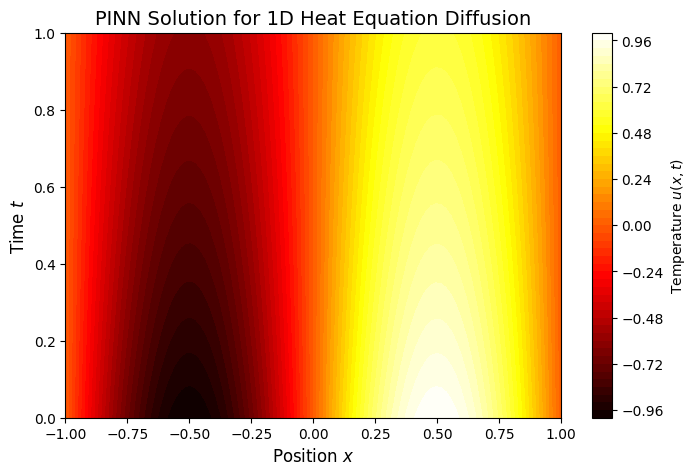

In [8]:
# Create grid for visualization
nx, nt = 100, 100
x_grid = np.linspace(-1, 1, nx)
t_grid = np.linspace(0, 1, nt)
X, T = np.meshgrid(x_grid, t_grid)

# Flatten for model evaluation
x_test = torch.tensor(X.flatten(), dtype=torch.float32).view(-1, 1)
t_test = torch.tensor(T.flatten(), dtype=torch.float32).view(-1, 1)

model.eval()
with torch.no_grad():
    U_pred = model(x_test, t_test).numpy().reshape(nt, nx)

# Plotting the heatmap / contour of temperature diffusion
plt.figure(figsize=(8, 5))
plt.contourf(X, T, U_pred, levels=50, cmap='hot')
plt.colorbar(label='Temperature $u(x,t)$')
plt.xlabel('Position $x$', fontsize=12)
plt.ylabel('Time $t$', fontsize=12)
plt.title('PINN Solution for 1D Heat Equation Diffusion', fontsize=14)
plt.show()

How Inverse Modeling WorksInitial Guess: Start with a wrong or random guess for the physical parameter (e.g., assume $\nu = 0.1$).Joint Optimization: As the network trains, gradients flow from the physics residual not just into the neural network weights, but also into $\nu$.Data Constraint: By feeding a few sparse measurements of the true system, the optimizer tunes $\nu$ until the physical law matches reality.

In [9]:
import torch
import torch.nn as nn
import numpy as np

class InverseHeatPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        
        # Make the unknown diffusion coefficient a trainable parameter!
        # Initial guess: 0.1 (True value is 0.05)
        self.nu = nn.Parameter(torch.tensor([0.1], dtype=torch.float32))
        
    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        return self.net(inputs)

model = InverseHeatPINN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

# Physics residual function using the trainable self.nu
def physics_loss(model, x, t):
    x.requires_grad_(True)
    t.requires_grad_(True)
    
    u = model(x, t)
    
    u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    
    # Use model.nu dynamically
    residual = u_t - model.nu * u_xx
    return torch.mean(residual**2)

In [10]:
# Simulate sparse sensor data (e.g., 50 random internal measurements)
x_data = torch.rand(50, 1) * 2 - 1
t_data = torch.rand(50, 1)
# Generate synthetic "true" measurements using nu = 0.05 (for demonstration)
# In reality, this would be experimental sensor data.
u_data = torch.sin(np.pi * x_data) * torch.exp(-0.05 * (np.pi**2) * t_data)

epochs = 3000
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # 1. PDE collocation loss
    x_col = torch.rand(500, 1) * 2 - 1
    t_col = torch.rand(500, 1)
    loss_pde = physics_loss(model, x_col, t_col)
    
    # 2. Sparse data loss (sensor measurements)
    pred_data = model(x_data, t_data)
    loss_data = torch.mean((pred_data - u_data)**2)
    
    # Total loss combines physics constraint + data fitting
    loss = loss_pde + 10.0 * loss_data
    
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch+1} | Loss: {loss.item():.5f} | Estimated nu: {model.nu.item():.5f}")

print(f"\nFinal Estimated Diffusion Coefficient: {model.nu.item():.5f} (True value was 0.05)")

Epoch 500 | Loss: 0.00191 | Estimated nu: 0.04912
Epoch 1000 | Loss: 0.00053 | Estimated nu: 0.04965
Epoch 1500 | Loss: 0.00104 | Estimated nu: 0.04922
Epoch 2000 | Loss: 0.00032 | Estimated nu: 0.04921
Epoch 2500 | Loss: 0.00023 | Estimated nu: 0.05012
Epoch 3000 | Loss: 0.00019 | Estimated nu: 0.05004

Final Estimated Diffusion Coefficient: 0.05004 (True value was 0.05)
